# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

**Rules:** label every output, e.g. `print("T5a:", ...)` · use `random_state=42` for the split · written answers go in Markdown cells · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab05/Lab05.ipynb` by the deadline announced in class (11:59 PM PKT).

Name: Syeda Khadija Hassan  Roll No: 2024-SE-09

### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).

T1a: shape of the full data = (20484, 11)
T1b: shape of gli = (796, 11)
T1c: summary statistics
              Age  Price_lakh
count  796.000000  796.000000
mean     6.445980   16.586237
std      3.107847    3.984407
min      2.000000    6.543210
25%      4.000000   13.500000
50%      6.000000   16.500000
75%      9.000000   19.500000
max     15.000000   30.000000
T1d: correlation (Age, Price_lakh) = -0.896


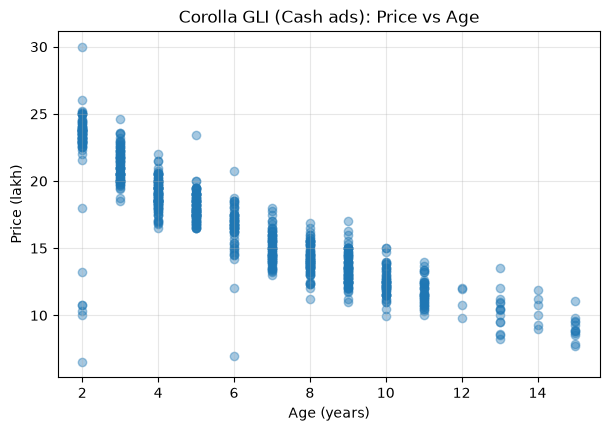

In [2]:
# T1a: load the data
df = pd.read_csv("pakistan_used_cars_clean.csv")
print("T1a: shape of the full data =", df.shape)

# T1b: Corolla GLI, Cash ads, Year 2005-2018, Price_lakh between 5 and 40
gli = df[(df["Model"] == "Corolla GLI")
         & (df["Transaction Type"] == "Cash")
         & (df["Year"].between(2005, 2018))
         & (df["Price_lakh"].between(5, 40))].copy()
print("T1b: shape of gli =", gli.shape)

# T1c: summary statistics of Age and Price_lakh
print("T1c: summary statistics")
print(gli[["Age", "Price_lakh"]].describe())

# T1d: correlation between Age and Price_lakh
corr = gli["Age"].corr(gli["Price_lakh"])
print("T1d: correlation (Age, Price_lakh) =", round(corr, 3))

# T1e: scatter plot of Price_lakh against Age
plt.figure(figsize=(7, 4.5))
plt.scatter(gli["Age"], gli["Price_lakh"], alpha=0.4)
plt.title("Corolla GLI (Cash ads): Price vs Age")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh)")
plt.grid(alpha=0.3)
plt.show()


**T1 answer:** Yes, a straight line is a sensible model for this data. The correlation between `Age` and `Price_lakh` is **-0.896**, which is strong and negative: as a Corolla GLI gets older, its price goes down. The scatter plot agrees. The points form a clear downward band, from about 23-25 lakh at age 2 to about 9 lakh at age 15. The band bends slightly: prices drop faster in the first few years (roughly 23.5 to 18 lakh between ages 2 and 5) than in the later years (roughly 12 to 9 lakh between ages 10 and 15), so a straight line is a good approximation but not perfect. The points are also not exactly on a line, because each ad is a different car (mileage, condition, asking price), and a few ads are far from the band.

## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.

In [3]:
# T2a: features and target (X must be 2-D, y 1-D)
X = gli[["Age"]]
y = gli["Price_lakh"]
print("T2a: X shape =", X.shape, "| y shape =", y.shape)

# T2b: 80 % train / 20 % test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("T2b: X_train =", X_train.shape, "| X_test =", X_test.shape,
      "| y_train =", y_train.shape, "| y_test =", y_test.shape)


T2a: X shape = (796, 1) | y shape = (796,)
T2b: X_train = (636, 1) | X_test = (160, 1) | y_train = (636,) | y_test = (160,)


## Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.

In [4]:
# T3a: means of the training data
x_bar = np.mean(X_train["Age"])
y_bar = np.mean(y_train)
print("T3a: x_bar =", round(x_bar, 4), "| y_bar =", round(y_bar, 4))

# T3b: least squares formulas (training data only)
x = X_train["Age"].to_numpy()
yv = y_train.to_numpy()
b1 = np.sum((x - x_bar) * (yv - y_bar)) / np.sum((x - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
print("T3b: b1 (slope) =", round(b1, 3), "lakh per year")
print("T3b: b0 (intercept) =", round(b0, 3), "lakh")


T3a: x_bar = 6.3821 | y_bar = 16.6533
T3b: b1 (slope) = -1.146 lakh per year
T3b: b0 (intercept) = 23.967 lakh


**T3c answer:**
- **b₁ = -1.146 lakh per year (slope).** For every extra year of age, the expected price of a Corolla GLI drops by about 1.15 lakh (roughly Rs 114,600).
- **b₀ = 23.97 lakh (intercept).** This is the price the line predicts at age 0, a brand-new car. It is only a rough reference point, because the data starts at age 2, so age 0 is outside what the model has seen.

## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.

In [5]:
# T4a: create, fit on the training data, and print the parameters
model = LinearRegression()
model.fit(X_train, y_train)
print("T4a: coef_ (slope) =", model.coef_)
print("T4a: intercept_ =", model.intercept_)

# T4b: compare with the NumPy values from Task 3
print("T4b: slope matches Task 3:", np.isclose(model.coef_[0], b1))
print("T4b: intercept matches Task 3:", np.isclose(model.intercept_, b0))


T4a: coef_ (slope) = [-1.14595569]
T4a: intercept_ = 23.96690099419613
T4b: slope matches Task 3: True
T4b: intercept matches Task 3: True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.

In [6]:
# T5a: predictions and metrics with the formulas (NumPy)
y_pred = model.predict(X_test)
res = y_test.to_numpy() - y_pred            # residual = actual - predicted

mae = np.mean(np.abs(res))
mse = np.mean(res ** 2)
rmse = np.sqrt(mse)
sse = np.sum(res ** 2)
sst = np.sum((y_test.to_numpy() - y_test.mean()) ** 2)
r2 = 1 - sse / sst
print("T5a: MAE  =", round(mae, 3), "lakh")
print("T5a: MSE  =", round(mse, 3), "lakh^2")
print("T5a: RMSE =", round(rmse, 3), "lakh")
print("T5a: R2   =", round(r2, 3))

# T5b: check with sklearn.metrics
sk_mae = mean_absolute_error(y_test, y_pred)
sk_mse = mean_squared_error(y_test, y_pred)
sk_r2 = r2_score(y_test, y_pred)
print("T5b: sklearn MAE =", round(sk_mae, 3), "| MSE =", round(sk_mse, 3), "| R2 =", round(sk_r2, 3))
print("T5b: formulas match sklearn:",
      np.isclose(mae, sk_mae) and np.isclose(mse, sk_mse) and np.isclose(r2, sk_r2))

# T5c: train R2 vs test R2
train_r2 = r2_score(y_train, model.predict(X_train))
print("T5c: train R2 =", round(train_r2, 3), "| test R2 =", round(r2, 3))

# T5d: baseline that always predicts the training mean
baseline_pred = np.full(len(y_test), y_train.mean())
base_mae = mean_absolute_error(y_test, baseline_pred)
base_r2 = r2_score(y_test, baseline_pred)
print("T5d: baseline MAE =", round(base_mae, 3), "lakh | baseline R2 =", round(base_r2, 3))
print("T5d: model MAE is", round((1 - mae / base_mae) * 100, 1), "% smaller than the baseline MAE")


T5a: MAE  = 1.185 lakh
T5a: MSE  = 2.704 lakh^2
T5a: RMSE = 1.644 lakh
T5a: R2   = 0.845
T5b: sklearn MAE = 1.185 | MSE = 2.704 | R2 = 0.845
T5b: formulas match sklearn: True
T5c: train R2 = 0.79 | test R2 = 0.845
T5d: baseline MAE = 3.504 lakh | baseline R2 = -0.006
T5d: model MAE is 66.2 % smaller than the baseline MAE


**T5 answer:**
- **MAE = 1.185 lakh.** On unseen ads, the model's predicted price is off by about 1.18 lakh (roughly Rs 118,000) on average. RMSE is 1.644 lakh, a little larger than MAE, which means a few ads are missed by much more than the typical amount.
- **R² = 0.845.** Age alone explains about 84.5 % of the variation in Corolla GLI prices on the test ads. This is not "84.5 % accuracy"; it is the share of price variation the line explains compared with just guessing the average price.
- **Overfitting?** No. Train R² is 0.790 and test R² is 0.845, so the model does about as well on unseen ads as on the ads it learned from. (Test is slightly higher, which just reflects which ads landed in the test set.) With a single feature and two parameters, the model is too simple to memorise the training data.
- **Baseline.** Always predicting the training mean price gives MAE = 3.504 lakh and R² of about 0, as expected. The model's MAE of 1.185 lakh is about **66 % smaller**, so knowing the age makes the predictions much better than guessing the average.

## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?

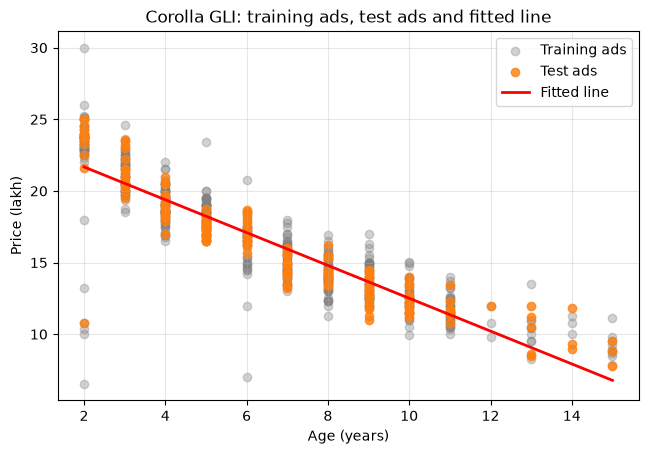

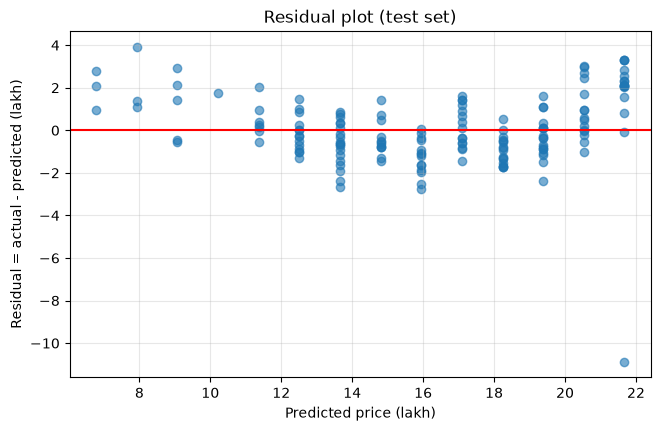

T6c: five largest errors on the test set
       Year  KMs Driven Registered City  Actual_lakh  Predicted_lakh  Error_lakh
18857  2018         NaN         Unknown        10.80           21.67      -10.87
20280  2006    220000.0       Islamabad        11.85            7.92        3.93
17363  2018         NaN         Unknown        25.00           21.67        3.33
18980  2018         NaN         Unknown        25.00           21.67        3.33
16557  2018       300.0         Unknown        25.00           21.67        3.33


In [7]:
# T6a: training ads (grey), test ads, and the fitted line
age_grid = pd.DataFrame({"Age": np.linspace(X["Age"].min(), X["Age"].max(), 100)})
plt.figure(figsize=(7.5, 4.8))
plt.scatter(X_train["Age"], y_train, color="grey", alpha=0.35, label="Training ads")
plt.scatter(X_test["Age"], y_test, color="tab:orange", alpha=0.8, label="Test ads")
plt.plot(age_grid["Age"], model.predict(age_grid), color="red", linewidth=2, label="Fitted line")
plt.title("Corolla GLI: training ads, test ads and fitted line")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# T6b: residual plot for the test set
plt.figure(figsize=(7.5, 4.5))
plt.scatter(y_pred, res, alpha=0.6)
plt.axhline(0, color="red", linewidth=1.5)
plt.title("Residual plot (test set)")
plt.xlabel("Predicted price (lakh)")
plt.ylabel("Residual = actual - predicted (lakh)")
plt.grid(alpha=0.3)
plt.show()

# T6c: the five test ads with the largest absolute error
test_ads = gli.loc[X_test.index, ["Year", "KMs Driven", "Registered City"]].copy()
test_ads["Actual_lakh"] = y_test
test_ads["Predicted_lakh"] = y_pred.round(2)
test_ads["Error_lakh"] = (y_test - y_pred).round(2)
test_ads["Abs_error"] = np.abs(y_test - y_pred)
top5 = test_ads.sort_values("Abs_error", ascending=False).head(5).drop(columns="Abs_error")
print("T6c: five largest errors on the test set")
print(top5)


**T6 answer:**
- **Residual plot.** There is no funnel: the spread of the residuals is similar at low and high predicted prices (apart from the outliers). But there is a **mild curve**: the residuals are mostly positive for the lowest predicted prices (the oldest cars), mostly negative in the middle, and positive again for the highest predicted prices (the newest cars). This U-shape means the line is too high in the middle and too low at both ends, which fits the slight bend seen in the scatter plot, where prices fall faster for young cars than for old ones. The straight line is still a fair model (most residuals are within about 2 lakh), but a curved model would fit a little better. The vertical stripes appear only because `Age` takes whole-number values, so every car of the same age gets the same prediction.
- **Largest errors.** The biggest miss is a 2018 car listed at 10.8 lakh while the model predicts about 21.7 lakh, an error of nearly 11 lakh. That price is far below similar 2018 cars, so it is most likely a **data mistake** (a wrong price, or a down payment entered instead of the full price), not a failure of the model. The other four large errors (three 2018 ads at a round 25 lakh and a 2006 car at 11.85 lakh) are 3-4 lakh above the line. They sit at the two ends of the age range, where the line is too low, so these are mostly **limits of the model**: it uses age only and cannot see mileage, condition or version. Some may also be optimistic asking prices.

## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?

In [8]:
# T7a: predict a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 - year)
years = [2018, 2015, 2010]
new_cars = pd.DataFrame({"Age": [2020 - yr for yr in years]})
pred_new = model.predict(new_cars)
for yr, age, p in zip(years, new_cars["Age"], pred_new):
    print(f"T7a: {yr} Corolla GLI (age {age}) -> {p:.2f} lakh")

# T7b: predict a 1995 Corolla GLI (age 25)
old_car = pd.DataFrame({"Age": [2020 - 1995]})
print("T7b: 1995 Corolla GLI (age 25) ->", round(model.predict(old_car)[0], 2), "lakh")


T7a: 2018 Corolla GLI (age 2) -> 21.67 lakh
T7a: 2015 Corolla GLI (age 5) -> 18.24 lakh
T7a: 2010 Corolla GLI (age 10) -> 12.51 lakh
T7b: 1995 Corolla GLI (age 25) -> -4.68 lakh


**T7 answer:** The prediction for the 1995 car is about **-4.68 lakh**, which is not believable, because a car cannot have a negative price. The model learned from ads aged 2 to 15 years, and age 25 is far outside that range. This is **extrapolation**: the straight line keeps going down forever even though real prices level off. The model should only be trusted inside the age range it was trained on.

## Task 8 · Reflection (Markdown cell)
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.

**Reflection:** I loaded the Corolla GLI cash ads and checked with a scatter plot and a correlation (-0.896) that a straight line made sense. I then split the data 80/20 with `random_state=42`, calculated the least squares line in NumPy on the training data, confirmed the same line with scikit-learn, and evaluated it on the test set with MAE, MSE, RMSE and R², a baseline, and a residual plot. The model is judged on the test set because those ads were never used for learning, so the score shows how it will do on new cars; a score on the training data would look too good. To a car buyer I would give the **MAE of about 1.2 lakh**, because its units are the same as the output (i.e.price of car) and says in lakh how far off a typical prediction is, whereas R² is harder to interpret. The main limitation of using age alone is that it ignores mileage, condition, version and city, which also affect price, and the model gives the same price to every car of the same age.